# 03 Evaluate: how good are the forecasts in the backtest?

**Purpose:** Compute the backtest errors of all candidate models, per horizon, in units a planner understands; compare them at the main horizon ($h = 2$), also without the crisis periods and year by year; check whether the indicators help (model family 2 against family 1) and which data lower the error the most; and choose the final model before the test.
**Input:** `../data/processed/backtest_forecasts.csv` (from `02_estimate.ipynb`), `backtest_forecasts_regression.csv` (`02b`, family 1: the series' own past), `backtest_forecasts_indicator.csv`, `../output/tables/02c_lasso_kept.csv` and `02c_conflict_lags.csv` (`02c`, family 2: with indicators).
**Output:** tables `03_*.csv` in `../output/tables/` (among them `03_backtest_errors.csv` and `03_two_models.csv`, read by `04_test.ipynb`) and figures `03_*.png` in `../output/figures/`.

This notebook uses **only the backtest** (2013 to September 2024). The test period stays untouched until we have chosen our final model (notebook 209, Step 7: choose before you test).

**Timeline.** The group fixed the choice rule and chose the linear regression on 17 November 2026 (commit `c6a3976`), then ran the test once (commit `4f284f5`). The random walk, the neighbouring countries and the conflict index were added afterwards, on the backtest only. The rule was not changed, and it still chooses the linear regression (section 9), so the test result of the chosen model is the same as in the first run. Model 2 and the other extensions were built after that first test, so their test results are for information only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the forecasts and compute the errors

For every forecast we compute two errors:

- the **absolute error in persons**, $|y - \hat y|$: the mean of it (MAE) says by how many applications per month we miss on average. This is the number a planner at SEM understands (notebook 108b, deck 08; notebook 209, Step 8).
- the **squared error in logs**, $(\log y - \widehat{\log y})^2$: its mean (MSE in logs) is what the regressions minimise, and its root (RMSE in logs) is the error measure of our project plan. An error of 0.10 in logs is roughly 10% off (notebook 209).

In [2]:
cols = ["model", "origin", "month", "h", "forecast_log", "actual_log", "forecast", "actual"]
files = ["backtest_forecasts.csv",              # 02: simple rules and (S)ARIMA
         "backtest_forecasts_regression.csv",   # 02b: family 1, the series' own past
         "backtest_forecasts_indicator.csv"]    # 02c: family 2, with indicators
forecasts = pd.concat([pd.read_csv("../data/processed/" + f)[cols] for f in files], ignore_index=True)
forecasts["month"] = pd.to_datetime(forecasts["month"])
forecasts["origin"] = pd.to_datetime(forecasts["origin"])

forecasts["abs_error"] = (forecasts["actual"] - forecasts["forecast"]).abs()
forecasts["sq_error_log"] = (forecasts["actual_log"] - forecasts["forecast_log"]) ** 2

print("Forecasts:", forecasts.shape[0], "| models:", forecasts["model"].nunique(),
      "| forecast months from", forecasts["month"].min(), "to", forecasts["month"].max())
print("Same forecast months for all models:",
      forecasts.groupby(["model", "h"])["month"].apply(lambda m: tuple(sorted(m))).groupby("h").nunique().eq(1).all())

Forecasts: 7980 | models: 19 | forecast months from 2013-01-01 00:00:00 to 2024-09-01 00:00:00
Same forecast months for all models: True


## 2. Errors of all models for all horizons

We put the simple rules first (the two of our plan and the random walk), then the SARIMA model (`02`), **family 1**, the three regressions on the series' own past (`02b`), **family 2**, the same three regressions with each indicator (routes, neighbouring countries, conflict index) and with all three (`02c`). All models were evaluated on exactly the same forecast months (notebook 209: the same folds and the same error measure for all).

In [3]:
baselines = ["Seasonal naive", "12-month average"]                  # the simple rules of our plan
simple_rules = baselines + ["Random walk"]
sarima_models = ["SARIMA(0,1,1)(0,1,1)12"]                           # benchmark from notebook 202
regression_models = ["Linear regression", "Ridge", "Lasso"]           # family 1
combos = ["routes", "neighbours", "conflict", "all indicators"]      # each indicator alone, and all three
indicator_models = [f"{m} + {c}" for c in combos for m in regression_models]   # family 2
model_order = simple_rules + sarima_models + regression_models + indicator_models

# One fixed colour per model (plt.cm.tab10, notebook 211); a model with indicators gets the colour of
# the same regression without them (and a dashed line in the figures)
colors = dict(zip(baselines + sarima_models + regression_models, plt.cm.tab10([0, 1, 4, 5, 6, 7])))
colors["Random walk"] = plt.cm.tab10(8)
for name in indicator_models:
    colors[name] = colors[name.split(" + ")[0]]

def error_table(data):
    # MAE in persons, MSE and RMSE in logs for every model and horizon
    grouped = data.groupby(["model", "h"])
    table = pd.DataFrame({
        "MAE (persons)": grouped["abs_error"].mean(),
        "MSE (log)": grouped["sq_error_log"].mean(),
        "RMSE (log)": np.sqrt(grouped["sq_error_log"].mean()),
        "forecasts": grouped["abs_error"].size(),
    }).reset_index()
    return table

errors = error_table(forecasts)
mae = errors.pivot(index="model", columns="h", values="MAE (persons)").loc[model_order].round(0)
mae.columns = [f"MAE h={h}" for h in mae.columns]
rmse = errors.pivot(index="model", columns="h", values="RMSE (log)").loc[model_order].round(3)
rmse.columns = [f"RMSE log h={h}" for h in rmse.columns]
overview = pd.concat([mae, rmse], axis=1)
overview.to_csv("../output/tables/03_backtest_errors.csv")
overview

,MAE h=1,MAE h=2,MAE h=3,RMSE log h=1,RMSE log h=2,RMSE log h=3
model,,,,,,
Seasonal naive,679.0,681.0,682.0,0.436,0.437,0.438
12-month average,487.0,528.0,558.0,0.317,0.342,0.362
Random walk,259.0,379.0,487.0,0.195,0.288,0.358
"SARIMA(0,1,1)(0,1,1)12",254.0,369.0,458.0,0.191,0.274,0.328
Linear regression,256.0,358.0,452.0,0.197,0.278,0.333
Ridge,248.0,358.0,447.0,0.187,0.279,0.336
Lasso,254.0,360.0,450.0,0.193,0.281,0.338
Linear regression + routes,266.0,373.0,483.0,0.203,0.282,0.340
Ridge + routes,253.0,364.0,464.0,0.191,0.281,0.340


**What we see.**
- At every horizon, the two simple rules of our plan have the largest errors: the seasonal naive about 680 persons, the 12-month average 487 to 558. The random walk is much better (259, 379 and 487) and close to the models.
- Family 1 and the SARIMA model are close to each other: at $h = 2$ the three regressions are at 358, 358 and 360, SARIMA at 369.
- **Family 2 is not better than family 1 at $h = 2$:** 357 to 401 against 358 to 360. The only model below its own model is Ridge with the conflict index (357.3 against 357.9 for Ridge, less than one person). With all three indicators the linear regression rises to 401 (524 at $h = 3$): with 20 features it overfits (notebook 105).
- An indicator is lowest only at a single horizon: at $h = 1$ Ridge with the neighbours (240 against 248).
- The two error measures do not crown the same model: by MAE Ridge with the conflict index is lowest at $h = 2$ (357), by RMSE in logs SARIMA (0.274).

## 3. The main comparison: $h = 2$

Our project plan fixes one main comparison (Johannes' feedback): the **best simple baseline** against the **best model**, at the main horizon $h = 2$, by MAE in persons. The baselines of our plan are the seasonal naive and the 12-month average; we also report the comparison with the random walk, the simplest rule of all. We read everything from the table above with code, so that nothing is chosen by hand.

In [4]:
h2 = errors[errors["h"] == 2].set_index("model")

best_baseline = h2.loc[baselines, "MAE (persons)"].idxmin()
best_sarima = h2.loc[sarima_models, "MAE (persons)"].idxmin()
best_regression = h2.loc[regression_models, "MAE (persons)"].idxmin()
best_indicator = h2.loc[indicator_models, "MAE (persons)"].idxmin()
best_model = h2.loc[sarima_models + regression_models + indicator_models, "MAE (persons)"].idxmin()

for label, name in [("Best simple baseline", best_baseline), ("Random walk", "Random walk"),
                    ("SARIMA model", best_sarima), ("Best of family 1", best_regression),
                    ("Best of family 2", best_indicator), ("Best model overall", best_model)]:
    print(f"{label + ' at h=2:':26s} {name:32s} MAE {h2.loc[name, 'MAE (persons)']:5.1f} persons   "
          f"RMSE (log) {h2.loc[name, 'RMSE (log)']:.3f}")
print()
for rule in [best_baseline, "Random walk"]:
    print(f"Best model against {rule}: {100 * (1 - h2.loc[best_model, 'MAE (persons)'] / h2.loc[rule, 'MAE (persons)']):.0f}% lower MAE, "
          f"{100 * (1 - h2.loc[best_model, 'RMSE (log)'] / h2.loc[rule, 'RMSE (log)']):.0f}% lower RMSE (log)")
print(f"For comparison, average actual number of applications in these months: {forecasts[forecasts['h'] == 2]['actual'].mean():.0f}")

Best simple baseline at h=2: 12-month average                 MAE 527.7 persons   RMSE (log) 0.342
Random walk at h=2:        Random walk                      MAE 378.5 persons   RMSE (log) 0.288
SARIMA model at h=2:       SARIMA(0,1,1)(0,1,1)12           MAE 369.0 persons   RMSE (log) 0.274
Best of family 1 at h=2:   Ridge                            MAE 357.9 persons   RMSE (log) 0.279
Best of family 2 at h=2:   Ridge + conflict                 MAE 357.3 persons   RMSE (log) 0.281
Best model overall at h=2: Ridge + conflict                 MAE 357.3 persons   RMSE (log) 0.281

Best model against 12-month average: 32% lower MAE, 18% lower RMSE (log)
Best model against Random walk: 6% lower MAE, 3% lower RMSE (log)
For comparison, average actual number of applications in these months: 1850


**What we see.**
- The best simple baseline of our plan is the 12-month average (527.7 persons). The best model overall is Ridge with the conflict index (357.3, RMSE 0.281), practically the same as Ridge alone (357.9) and the linear regression (358.0): **32% lower MAE** and 18% lower RMSE (log) than the 12-month average. For comparison, there were on average 1,850 applications per month in these months.
- Against the random walk (378.5) the gain is only 6% by MAE and 3% by RMSE (log).
- Ridge is only 11 applications per month better than SARIMA (369.0), and by RMSE (log) the SARIMA model is slightly better.

**What this means for us.** Using the series' own past clearly beats the simple rules of our plan, by far more than the 10% of our success rule. Most of this gain comes from starting at the last known month, which the random walk also does; the regressions add the seasonal pattern on top.

## 4. Without the crisis periods

The backtest contains two exceptional periods: the 2015-16 crisis and the drop of 2020. As planned, we report the errors also without the forecast months of these years (2015-01 to 2016-12 and 2020-01 to 2020-12), and for the recent years only (from 2022). These are **evaluation periods**: the models themselves did not know about them.

In [5]:
month = forecasts["month"]
crisis = ((month >= "2015-01-01") & (month <= "2016-12-01")) | ((month >= "2020-01-01") & (month <= "2020-12-01"))

periods = {
    "all backtest months": forecasts,
    "without 2015-16 and 2020": forecasts[~crisis],
    "from 2022": forecasts[month >= "2022-01-01"],
}

rows = []
for period_name, data in periods.items():
    table = error_table(data[data["h"] == 2])
    table["period"] = period_name
    rows.append(table)
by_period = pd.concat(rows)

by_period.pivot(index="model", columns="period", values="MAE (persons)").loc[model_order, list(periods)].round(0)

period,all backtest months,without 2015-16 and 2020,from 2022
model,,,
Seasonal naive,681.0,523.0,681.0
12-month average,528.0,369.0,512.0
Random walk,379.0,309.0,488.0
"SARIMA(0,1,1)(0,1,1)12",369.0,295.0,427.0
Linear regression,358.0,286.0,413.0
Ridge,358.0,282.0,415.0
Lasso,360.0,288.0,420.0
Linear regression + routes,373.0,291.0,412.0
Ridge + routes,364.0,292.0,436.0


In [6]:
# Number of forecast months in each period (h = 2)
by_period[by_period["model"] == "Seasonal naive"].set_index("period")["forecasts"]

period
all backtest months         140
without 2015-16 and 2020    104
from 2022                    33
Name: forecasts, dtype: int64

**What we see.** (The three periods contain 140, 104 and 33 forecast months.)
- Without 2015-16 and 2020, all errors are smaller. The best are Ridge with the conflict index (274), the linear regression with the conflict index (280) and Ridge (282), against 295 for SARIMA, 309 for the random walk and 369 for the 12-month average.
- From 2022, the linear regression with indicators is lowest (405 with the neighbours, 410 with the conflict index, like Ridge with it), before the linear regression alone (413) and Ridge (415), but over only 33 months; the random walk is at 488.

**What this means for us.** The best model changes from one period to the next: the regressions with and without indicators trade places. Their differences are small compared with how much the errors change between periods.

## 5. Is the difference real, or within the noise? Year by year

Notebook 209 compares models fold by fold: each validation fold gives one error, and we look at whether the gap between two models is larger than the spread across the folds, and whether one model wins in most folds. In a time-series backtest, the natural "folds" are the **years**: we compute the MAE at $h = 2$ for each year of forecast months (2013 to 2024; 2013 starts in February and 2024 ends in September).

*Not seen in class:* `forecasts["month"].dt.year` gives the year of each forecast month.

In [7]:
h2_all = forecasts[forecasts["h"] == 2].copy()
h2_all["year"] = h2_all["month"].dt.year

by_year = h2_all.groupby(["year", "model"])["abs_error"].mean().reset_index()
by_year = by_year.pivot(index="year", columns="model", values="abs_error")[model_order].round(0)
by_year.columns.name = None
by_year.to_csv("../output/tables/03_backtest_errors_by_year_h2.csv")
by_year

,Seasonal naive,12-month average,Random walk,"SARIMA(0,1,1)(0,1,1)12",Linear regression,Ridge,Lasso,Linear regression + routes,Ridge + routes,Lasso + routes,Linear regression + neighbours,Ridge + neighbours,Lasso + neighbours,Linear regression + conflict,Ridge + conflict,Lasso + conflict,Linear regression + all indicators,Ridge + all indicators,Lasso + all indicators
year,,,,,,,,,,,,,,,,,,,
2013,640.0,392.0,255.0,216.0,244.0,207.0,234.0,226.0,211.0,227.0,264.0,253.0,262.0,221.0,224.0,230.0,391.0,259.0,257.0
2014,520.0,464.0,454.0,486.0,453.0,472.0,459.0,482.0,482.0,488.0,411.0,456.0,469.0,428.0,429.0,447.0,483.0,471.0,501.0
2015,1398.0,1501.0,670.0,787.0,730.0,704.0,668.0,782.0,629.0,666.0,757.0,703.0,680.0,852.0,740.0,726.0,924.0,674.0,668.0
2016,1727.0,1187.0,785.0,703.0,692.0,746.0,762.0,770.0,794.0,830.0,710.0,760.0,762.0,793.0,773.0,831.0,746.0,808.0,841.0
2017,760.0,430.0,207.0,183.0,162.0,161.0,170.0,194.0,180.0,182.0,187.0,163.0,180.0,164.0,162.0,177.0,218.0,193.0,195.0
2018,237.0,171.0,143.0,187.0,166.0,148.0,174.0,169.0,154.0,184.0,164.0,147.0,172.0,156.0,145.0,178.0,157.0,150.0,174.0
2019,112.0,72.0,120.0,136.0,149.0,135.0,145.0,148.0,137.0,139.0,152.0,137.0,145.0,158.0,117.0,149.0,152.0,131.0,139.0
2020,286.0,267.0,288.0,262.0,274.0,285.0,277.0,278.0,291.0,289.0,285.0,305.0,311.0,271.0,281.0,285.0,280.0,299.0,292.0
2021,440.0,297.0,176.0,190.0,190.0,192.0,175.0,190.0,190.0,187.0,192.0,192.0,184.0,188.0,188.0,189.0,219.0,219.0,214.0


In [8]:
def compare(a, b):
    # a against b at h = 2: change in MAE, wins year by year, gap of the averages, spread across years
    change = 100 * (h2.loc[a, "MAE (persons)"] / h2.loc[b, "MAE (persons)"] - 1)
    wins = int((by_year[a] < by_year[b]).sum())
    return {"model": a, "against": b, "MAE": round(h2.loc[a, "MAE (persons)"]), "MAE against": round(h2.loc[b, "MAE (persons)"]),
            "change in MAE (%)": round(change, 1), "years won (of 12)": wins,
            "gap of the yearly averages": round(by_year[b].mean() - by_year[a].mean()),
            "spread across years (std of b)": round(by_year[b].std()),
            "success rule met": bool(change <= -10 and wins > by_year.shape[0] / 2)}

main = pd.DataFrame([compare(best_model, b) for b in simple_rules]
                    + [compare(best_regression, best_sarima), compare("Linear regression", "Random walk")]).set_index("model")
main.to_csv("../output/tables/03_main_comparison.csv")
main

,against,MAE,MAE against,change in MAE (%),years won (of 12),gap of the yearly averages,spread across years (std of b),success rule met
model,,,,,,,,
Ridge + conflict,Seasonal naive,357,681,-47.5,11,324,467,True
Ridge + conflict,12-month average,357,528,-32.3,9,168,417,True
Ridge + conflict,Random walk,357,379,-5.6,8,20,237,False
Ridge,"SARIMA(0,1,1)(0,1,1)12",358,369,-3.0,9,11,223,False
Linear regression,Random walk,358,379,-5.4,7,19,237,False


The picture follows notebook 209 (Step 5): each dot is one year, the black bar is the average over the years.

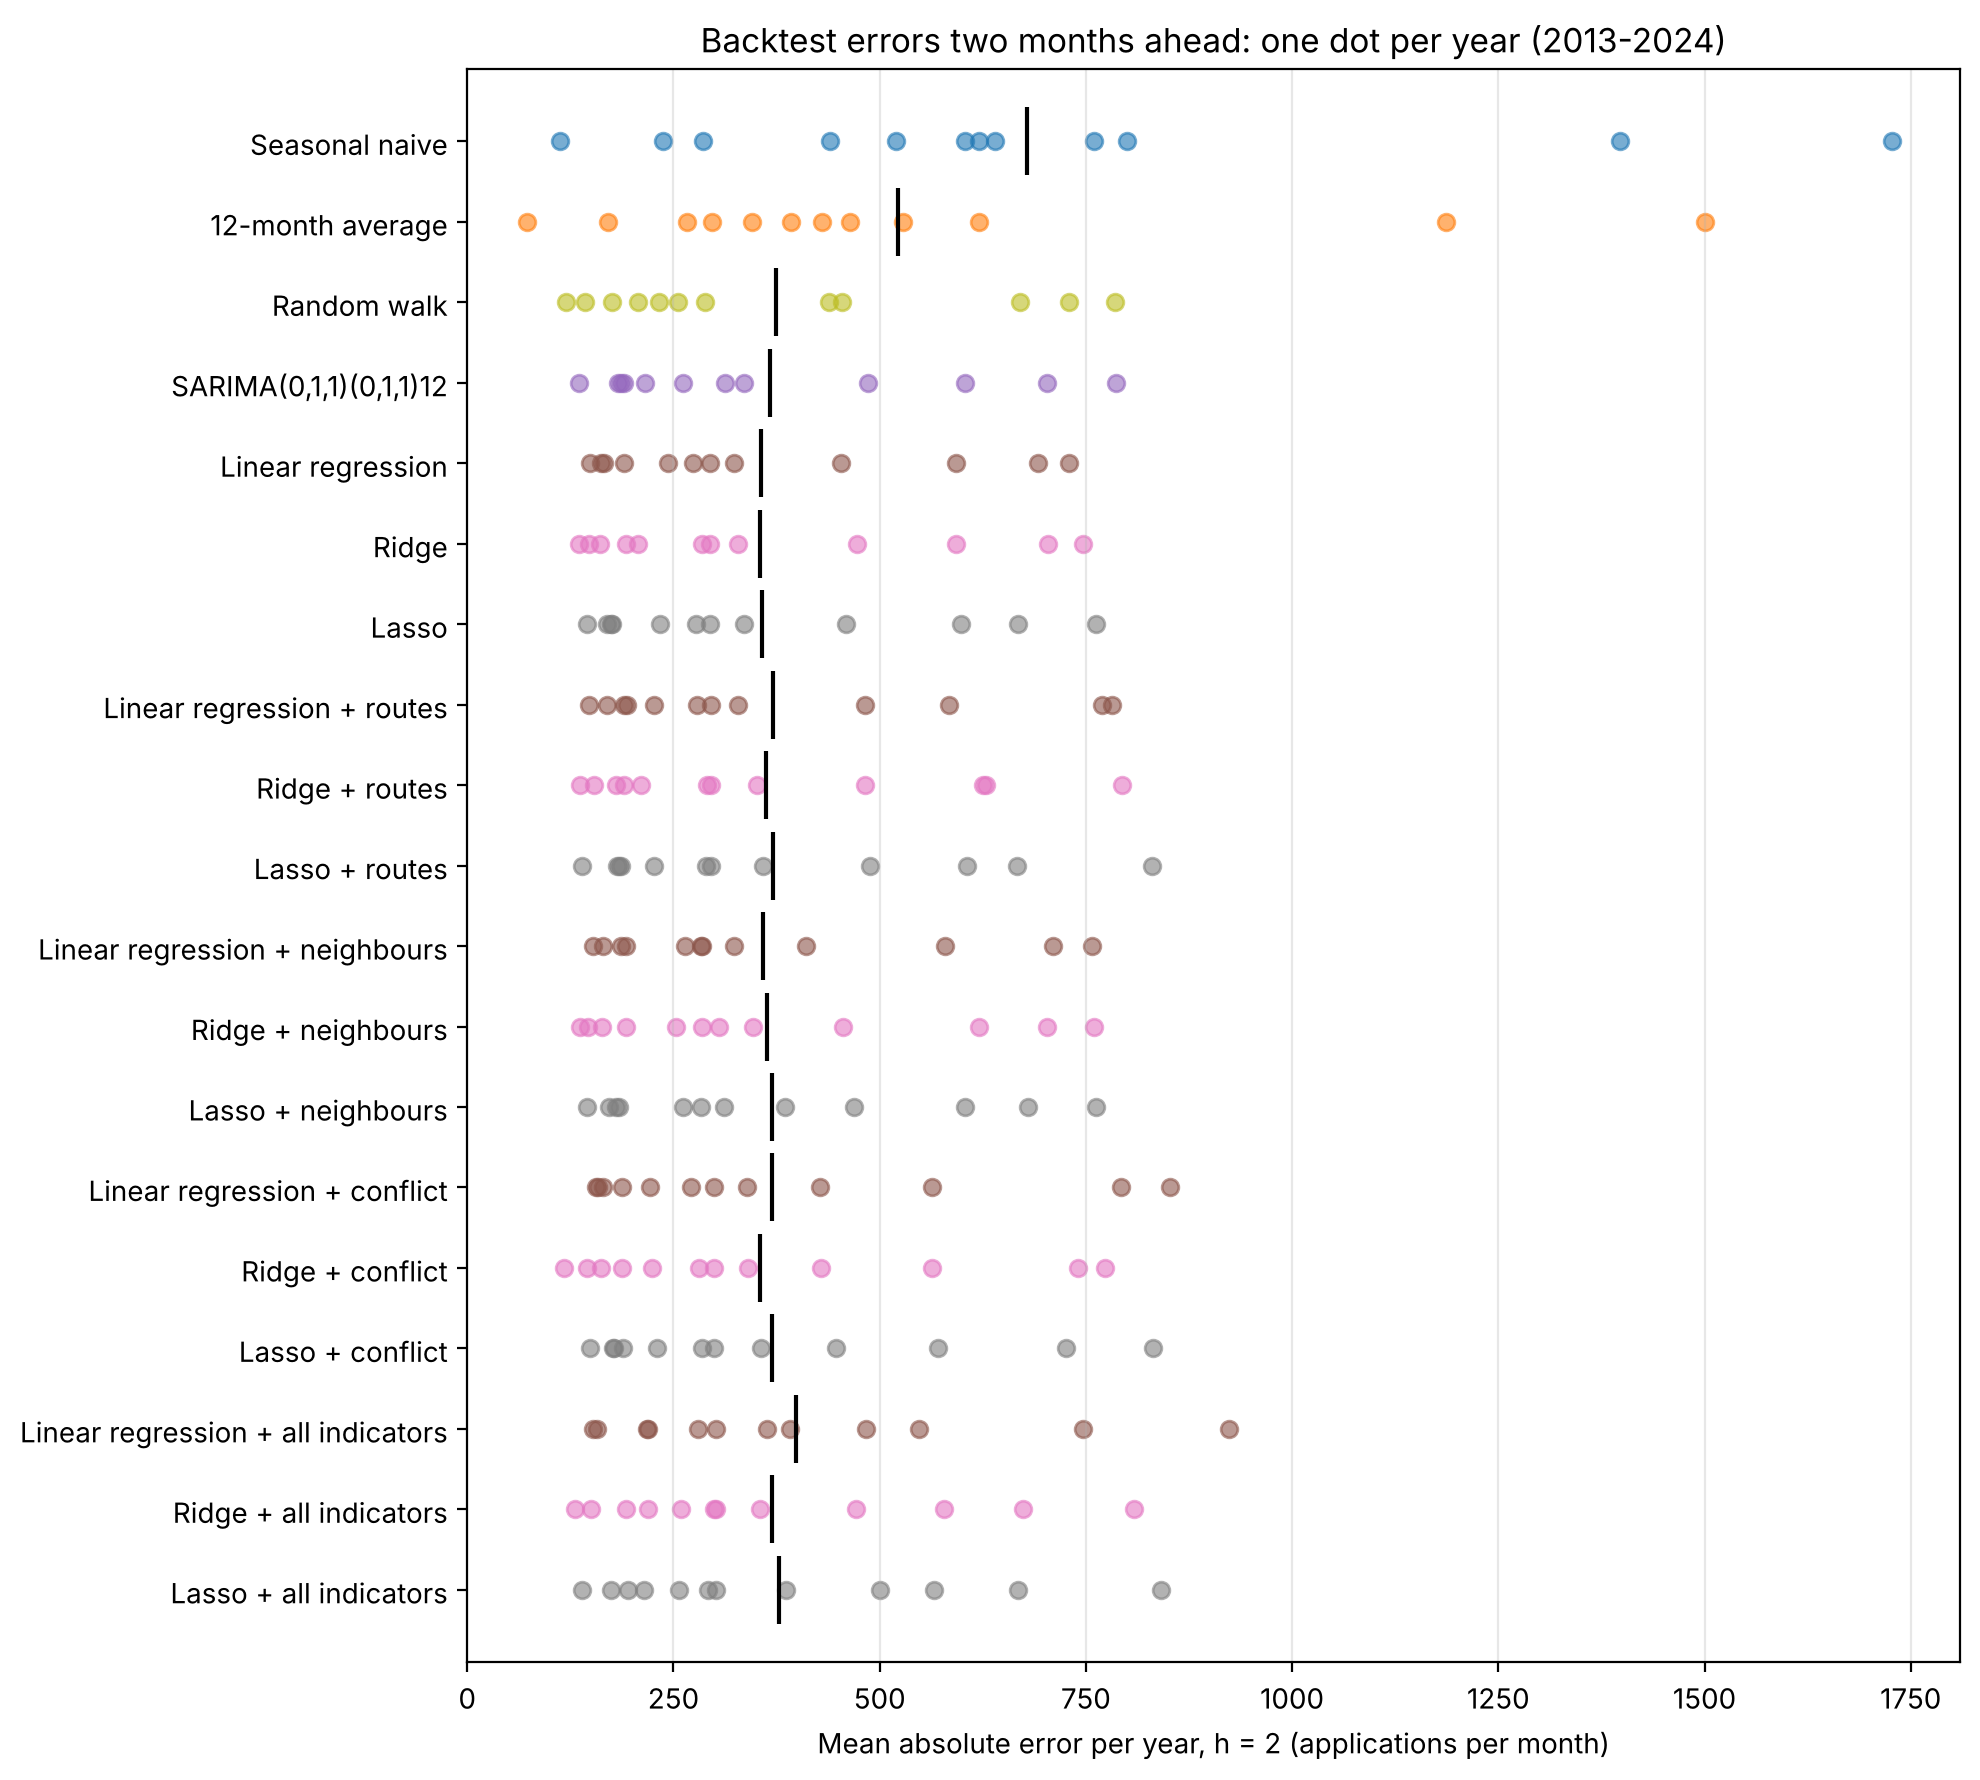

In [9]:
fig, ax = plt.subplots(figsize=(10, 9))
for i, name in enumerate(model_order):
    errors_by_year = by_year[name]
    ax.scatter(errors_by_year, [i] * len(errors_by_year), alpha=0.6, color=colors[name])
    ax.scatter([errors_by_year.mean()], [i], marker="|", s=600, color="black")
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_order)
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.set_xlabel("Mean absolute error per year, h = 2 (applications per month)")
ax.set_title("Backtest errors two months ahead: one dot per year (2013-2024)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_errors_by_year_h2.png")
plt.show()

**What we see.**
- **Best model against the simple rules:** Ridge with the conflict index has a lower MAE than the 12-month average in 9 of 12 years (gap of the averages 168, spread across years 417), and than the random walk in 8 (gap 20, spread 237); the linear regression beats the random walk in 7 years.
- **Best regression against SARIMA:** Ridge is lower in 9 of 12 years, but the gap is only 11 persons against a spread of about 220.
- In the picture, the own-history models and the models with indicators look almost the same: their averages (black bars) lie between about 357 and 401.

**What this means for us.** The advantage over the 12-month average is consistent; against the random walk it is small compared with the spread across years. Among the models, the differences are within the noise; when we choose before the test, a simpler model within the noise is a serious candidate (notebook 209, Step 7).

## 6. Errors over the horizon

How fast do the errors grow when we forecast further ahead? We plot the MAE of each model for $h = 1, 2, 3$.

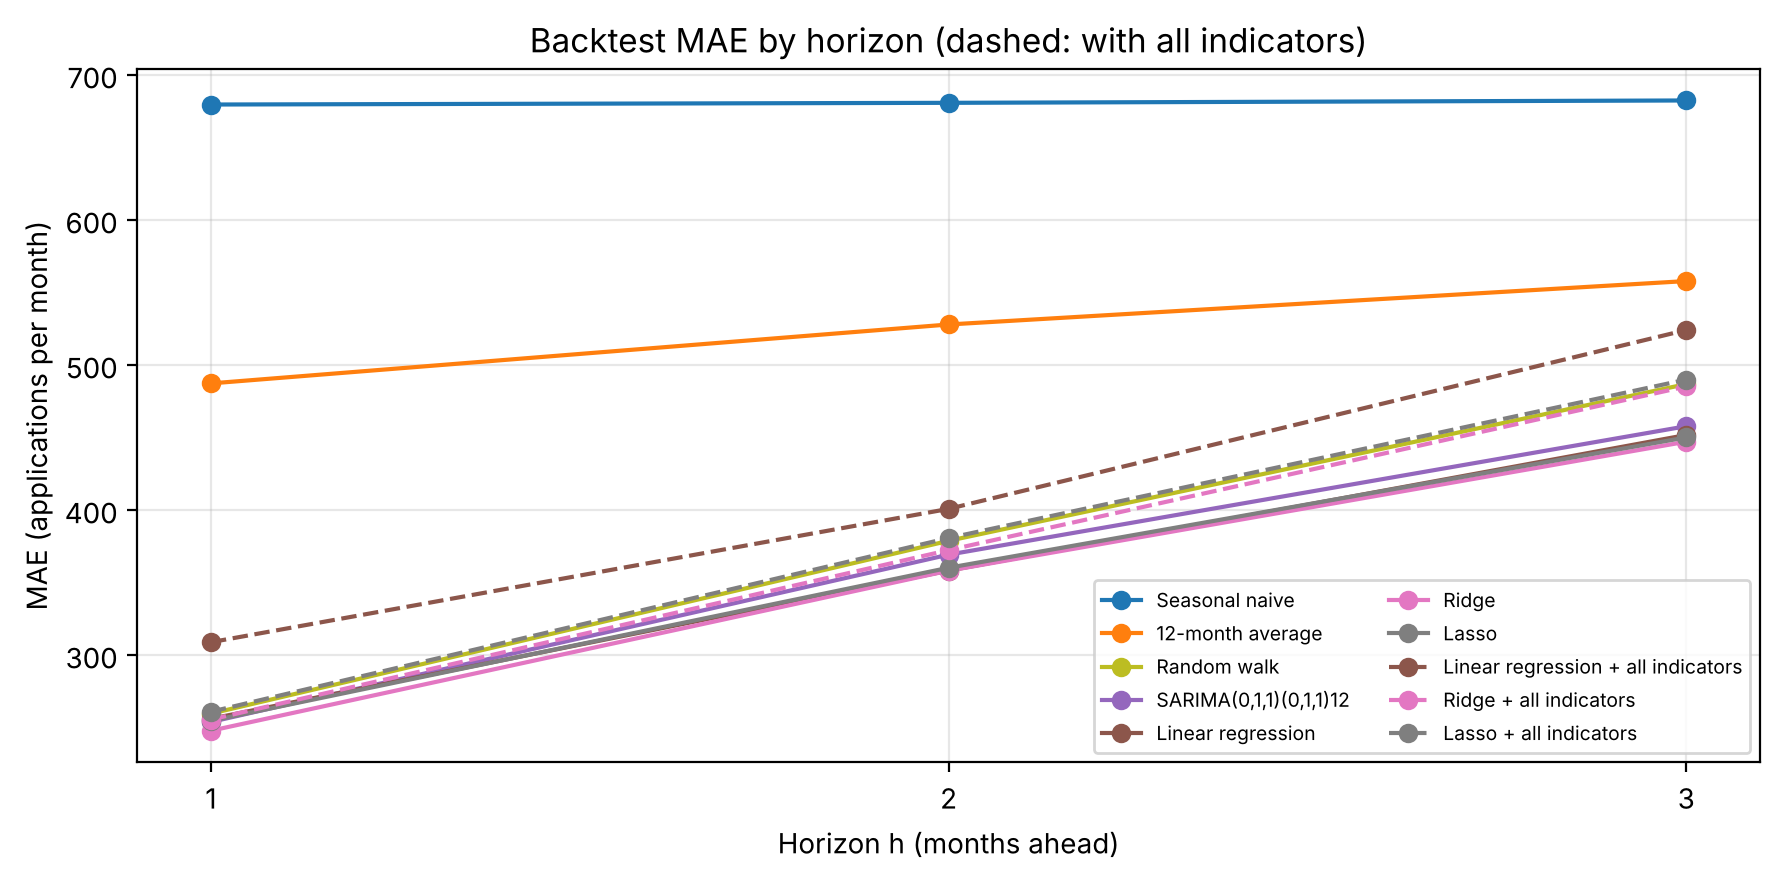

In [10]:
show = simple_rules + sarima_models + regression_models + [f"{m} + all indicators" for m in regression_models]
fig, ax = plt.subplots(figsize=(9, 4.5))
for name in show:
    one = errors[errors["model"] == name]
    style = "--" if name in indicator_models else "-"
    ax.plot(one["h"], one["MAE (persons)"], marker="o", linestyle=style, color=colors[name], label=name)
ax.set_xticks([1, 2, 3])
ax.set_xlabel("Horizon h (months ahead)")
ax.set_ylabel("MAE (applications per month)")
ax.set_title("Backtest MAE by horizon (dashed: with all indicators)")
ax.legend(fontsize=7, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_mae_by_horizon.png")
plt.show()

**What we see.** For the own-history models, the MAE grows from about 250 at $h = 1$ to 450 to 500 at $h = 3$, as expected (notebook 202). The dashed lines (all three indicators) lie above the solid lines of the same models at $h = 2$ and $h = 3$; at $h = 1$ Ridge and Lasso with indicators are close to those without (255 and 261 against 248 and 254), the linear regression is much worse (309 against 256). The random walk grows fastest (259 to 487): starting from the last month works one month ahead, much less three months ahead. The 12-month average grows slowly (487 to 558), and the seasonal naive stays flat at about 680.

## 7. Do the indicators help? Family 2 against family 1

Our project plan adds indicators **one block at a time**: every model of `02c` is a model of `02b` plus indicator features. So we compare each regression with its own versions with each indicator and with all three, on the same forecast months, at all horizons, by MAE and by MSE (log). A change counts as a clear improvement only if it lowers the MAE by at least 10% (success rule of our plan).

In [11]:
def effect_row(a, b, h, **info):
    # model a (with indicators) against model b (without), at horizon h
    e_a = errors[(errors["model"] == a) & (errors["h"] == h)].iloc[0]
    e_b = errors[(errors["model"] == b) & (errors["h"] == h)].iloc[0]
    return {**info, "h": h, "MAE without": e_b["MAE (persons)"], "MAE with": e_a["MAE (persons)"],
            "change in MAE (%)": 100 * (e_a["MAE (persons)"] / e_b["MAE (persons)"] - 1),
            "change in MSE log (%)": 100 * (e_a["MSE (log)"] / e_b["MSE (log)"] - 1)}

rows = []
for c in combos:
    for name in regression_models:
        for h in [1, 2, 3]:
            rows.append(effect_row(f"{name} + {c}", name, h, indicators=c, model=name))
indicator_effect = pd.DataFrame(rows)
indicator_effect.to_csv("../output/tables/03_indicator_effect.csv", index=False)
indicator_effect.pivot_table(index=["indicators", "model"], columns="h",
                             values=["change in MAE (%)", "change in MSE log (%)"], sort=False).round(1)

change in MAE (%)              \
h                                                1     2     3   
indicators     model                                             
routes         Linear regression               4.0   4.2   7.0   
               Ridge                           2.1   1.7   3.9   
               Lasso                          -1.6   3.8   3.8   
neighbours     Linear regression               3.3   0.9   3.1   
               Ridge                          -3.0   2.3   2.7   
               Lasso                          -2.2   3.4  -0.0   
conflict       Linear regression              11.8   3.9   8.4   
               Ridge                           4.6  -0.2   3.7   
               Lasso                          -1.2   3.4   5.3   
all indicators Linear regression              20.6  11.9  16.0   
               Ridge                           3.1   4.0   8.5   
               Lasso                           2.5   5.7   8.9   

                                 change in MSE log (%)              
h                                                    1     2     3  
indicators     model                                                
routes         Linear regression                   5.3   2.4   3.9  
               Ridge                               3.8   1.5   2.6  
               Lasso                              -2.8   3.3   4.0  
neighbours     Linear regression                   5.6   2.6   6.8  
               Ridge                              -1.8   4.3   4.6  
               Lasso                              -0.3   6.4   2.1  
conflict       Linear regression                  14.8   6.8  13.1  
               Ridge                               6.2   1.3   9.1  
               Lasso                              -1.8   4.6  11.0  
all indicators Linear regression                  27.6  13.4  19.4  
               Ridge                               4.5   6.0  12.2  
               Lasso                               3.8   8.4  13.9

**What we see.**
- At $h = 2$, **no indicator clearly improves** a model: the routes +1.7% to +4.2% MAE, the neighbours +0.9% to +3.4%, the conflict index −0.2% (Ridge) to +3.9% (with its lag chosen in each window), all three +4.0% to +11.9%. The MSE (log) rises in every case, also for Ridge with the conflict index (+1.3%).
- The only gains are small and at single horizons: at $h = 1$ the neighbours lower the MAE of Ridge and Lasso by 3.0% and 2.2%, the routes and the conflict index that of Lasso by 1.6% and 1.2%.
- No change comes close to the 10% of our success rule.

**What this means for us.** The indicators, as we can use them at the cutoff, do not improve the forecasts two months ahead. The routes and the neighbours move with Swiss applications in the same month, but at the cutoff we know them only up to $t-1$; the conflict index shows no lead at any lag (`01b`, section 14), and even its best lag, chosen in each window, changes the error by less than one person per month for Ridge.

The same comparison year by year at $h = 2$ (as in section 5) for each indicator alone and all three together, with the success rule: at least 10% lower MAE **and** a win in most years.

In [12]:
pairs = [(f"{m} + {c}", m) for c in combos for m in regression_models]
year_table = pd.DataFrame([compare(a, b) for a, b in pairs]).set_index("model")
year_table.drop(columns=["against"])

,MAE,MAE against,change in MAE (%),years won (of 12),gap of the yearly averages,spread across years (std of b),success rule met
model,,,,,,,
Linear regression + routes,373,358,4.2,3,-15,210,False
Ridge + routes,364,358,1.7,2,-6,220,False
Lasso + routes,374,360,3.8,3,-13,214,False
Linear regression + neighbours,361,358,0.9,4,-3,210,False
Ridge + neighbours,366,358,2.3,4,-8,220,False
Lasso + neighbours,372,360,3.4,2,-12,214,False
Linear regression + conflict,372,358,3.9,6,-14,210,False
Ridge + conflict,357,358,-0.2,6,0,220,False
Lasso + conflict,372,360,3.4,3,-12,214,False


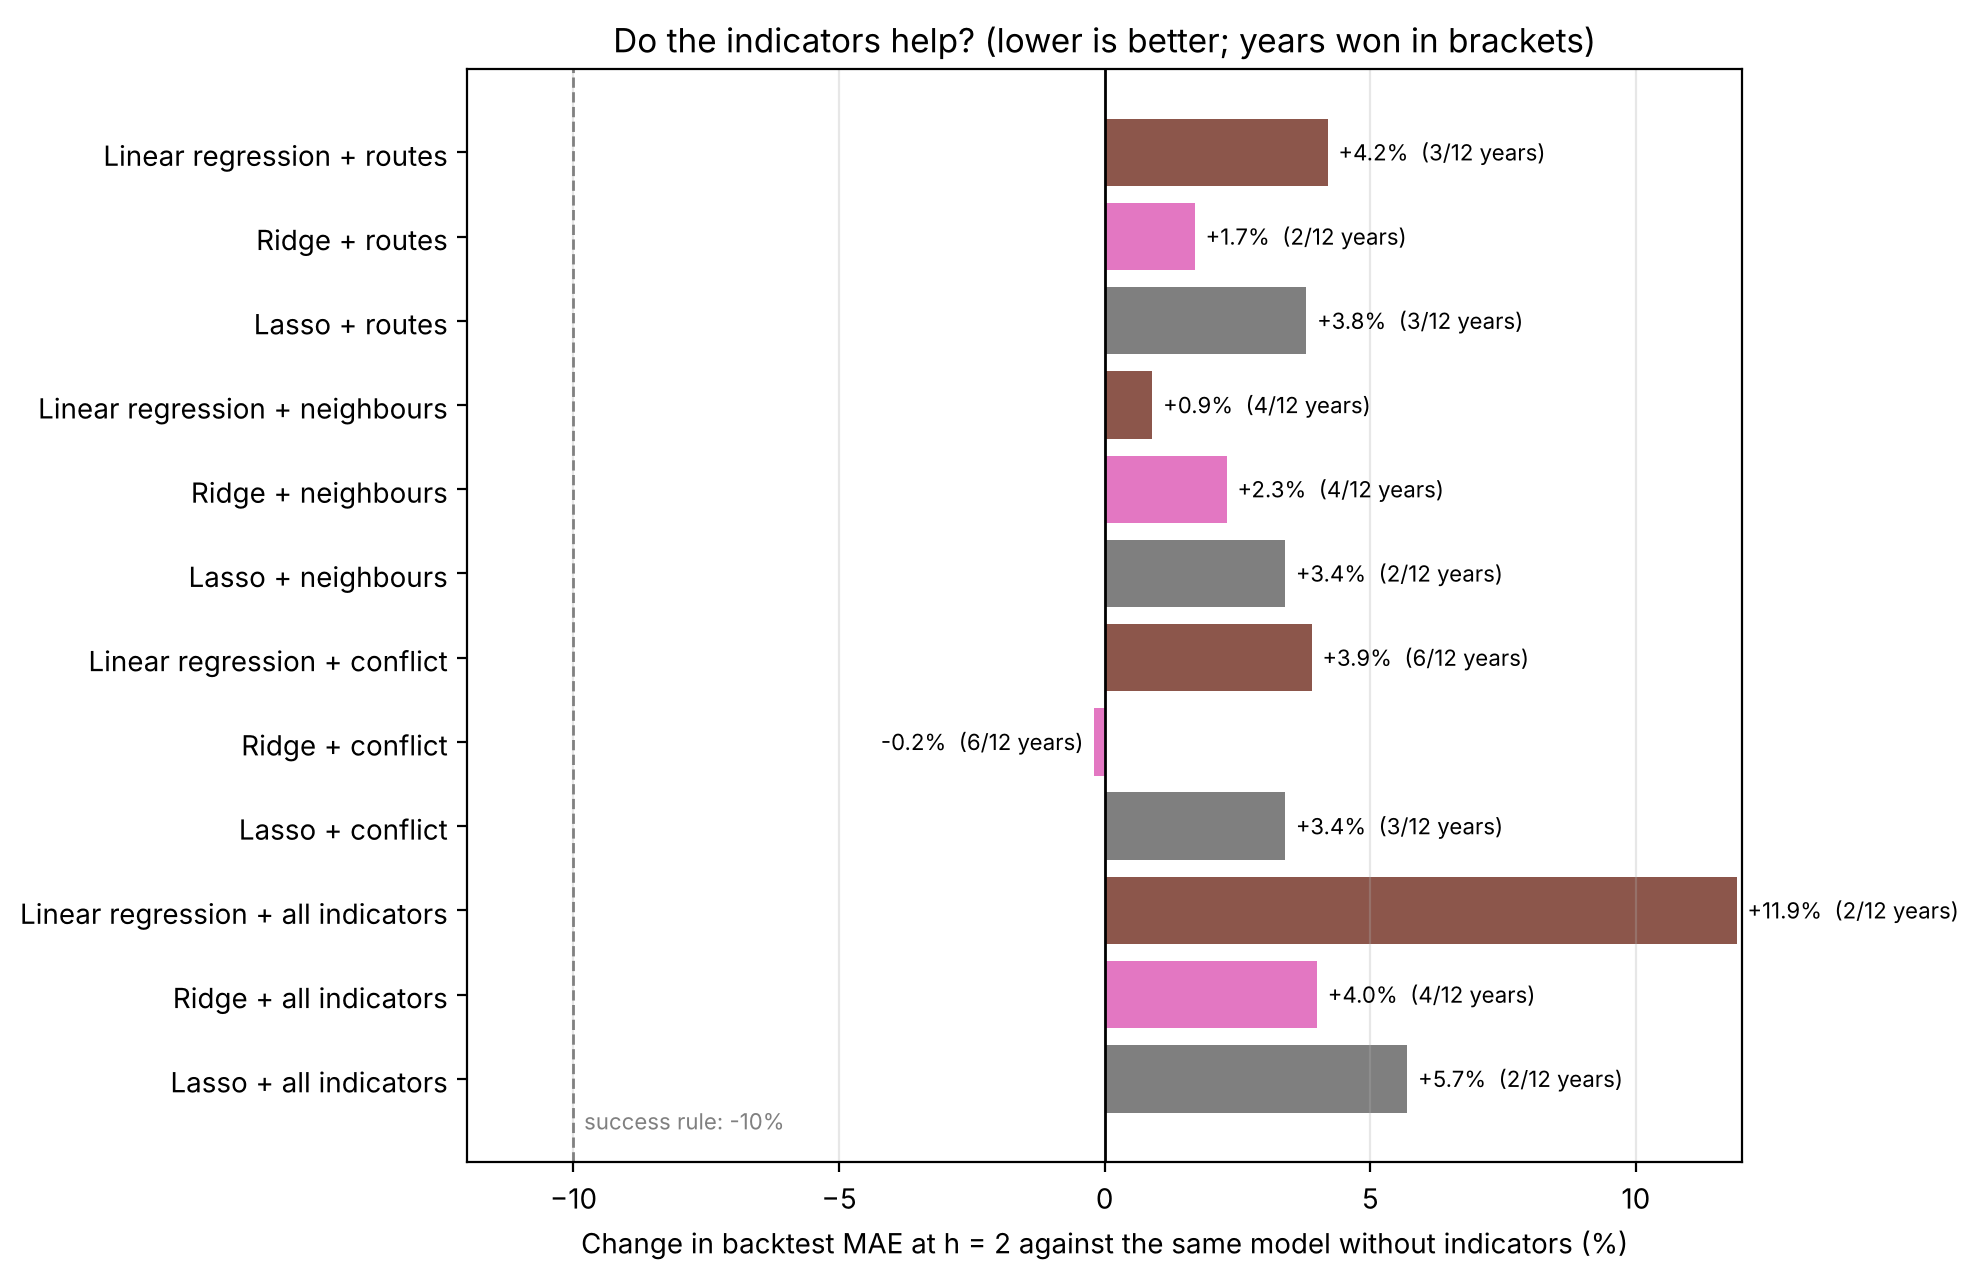

In [13]:
labels = [a for a, b in pairs]
values = [year_table.loc[a, "change in MAE (%)"] for a in labels]
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(range(len(labels)), values, color=[colors[a] for a in labels])
for i, a in enumerate(labels):
    ax.text(values[i] + (0.2 if values[i] >= 0 else -0.2), i, f"{values[i]:+.1f}%  ({year_table.loc[a, 'years won (of 12)']}/12 years)",
            va="center", ha="left" if values[i] >= 0 else "right", fontsize=8)
ax.axvline(0, color="black", linewidth=1)
ax.axvline(-10, color="grey", linestyle="--", linewidth=1)
ax.text(-9.8, len(labels) - 0.4, "success rule: -10%", color="grey", fontsize=8)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(-12, 12)
ax.set_xlabel("Change in backtest MAE at h = 2 against the same model without indicators (%)")
ax.set_title("Do the indicators help? (lower is better; years won in brackets)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/03_indicator_effect_h2.png")
plt.show()

**What we see.** Year by year at $h = 2$, the models with indicators beat their own model in only 2 to 6 of 12 years; the conflict index wins in 6 years with the linear regression and with Ridge, in 3 with Lasso. The gaps of the yearly averages lie between 0 (Ridge with the conflict index) and −43 persons, so none favours the models with indicators, and all are small against the spread across years (about 210 to 220). No model meets the success rule. In the figure, every bar lies right of 0 except Ridge with the conflict index (−0.2%).

**What this means for us.** Following our plan (one block at a time, keep it only if it helps), **we keep no indicator**. We report this as a result: two months ahead, the past of the Swiss series already contains what the indicators can tell us in time.

### Which data lower the error the most?

We rank the indicators by how much each one alone changes the MSE (log) of the own-history model (from the table above), at each horizon and on average over the three regressions. Then the lags of the conflict index chosen in `02c`, and Lasso's own answer when all three are available: at how many origins it keeps each indicator feature.

In [14]:
single = indicator_effect[indicator_effect["indicators"] != "all indicators"]
ranking = single.pivot_table(index="indicators", columns=["h", "model"], values="change in MSE log (%)", sort=False).round(1)
ranking.to_csv("../output/tables/03_indicator_ranking.csv")
print("Change in MSE (log) when one indicator is added to the own-history model (negative = it lowers the error)")
print(ranking.to_string())
print()
print("Average over the three regressions at h = 2:")
print(single[single["h"] == 2].groupby("indicators", sort=False)["change in MSE log (%)"].mean().round(1).sort_values().to_string())
print()
lags = pd.read_csv("../output/tables/02c_conflict_lags.csv", index_col=["combination", "h"])
print("Lag of the conflict index chosen in each window, all indicators (share of origins):")
print((lags.loc["all indicators"].div(lags.loc["all indicators"].sum(axis=1), axis=0)).round(2).to_string())
print()
pd.read_csv("../output/tables/02c_lasso_kept.csv", index_col="feature")

Change in MSE (log) when one indicator is added to the own-history model (negative = it lowers the error)
h                          1                 2                 3     1     2     3     1     2     3
model      Linear regression Linear regression Linear regression Ridge Ridge Ridge Lasso Lasso Lasso
indicators                                                                                          
routes                   5.3               2.4               3.9   3.8   1.5   2.6  -2.8   3.3   4.0
neighbours               5.6               2.6               6.8  -1.8   4.3   4.6  -0.3   6.4   2.1
conflict                14.8               6.8              13.1   6.2   1.3   9.1  -1.8   4.6  11.0

Average over the three regressions at h = 2:
indicators
routes        2.4
conflict      4.3
neighbours    4.4

Lag of the conflict index chosen in each window, all indicators (share of origins):
   lag 0  lag 1  lag 2  lag 3  lag 4  lag 5  lag 6  lag 7  lag 8  lag 9  lag 10  lag 11  lag

,indicator,share of origins kept,mean coefficient
feature,,,
routes_change_last_month,routes,0.80,0.012
routes_change_3_months,routes,0.40,-0.010
neighbours_change_last_month,neighbours,0.39,0.004
neighbours_change_3_months,neighbours,0.49,-0.021
conflict_change_last_month,conflict,0.52,-0.003
conflict_change_3_months,conflict,0.50,0.005


**What we see.**
- **Ranking of the indicators** (each one alone, change in MSE (log) at $h = 2$, average of the three regressions): the routes +2.4%, the conflict index +4.3%, the neighbours +4.4%. So the routes hurt the least, but **none lowers the error** at $h = 2$. The only decreases are at $h = 1$ (Lasso with the routes −2.8% or the conflict index −1.8%, Ridge with the neighbours −1.8%).
- **The lag of the conflict index** chosen in each window spreads over most lags: at $h = 2$ the most frequent are lag 5 (25% of the origins), lag 12 (15%), lags 0 and 3 (14% each); none is chosen at most origins.
- **Lasso with all three** keeps the monthly route change at 80% of the origins, the other indicator features at 39% to 52%.

**What this means for us.** The routes are the most useful indicator, and both Lasso and the ranking agree that the newest route month is the only feature with a small, steady signal. It is still not enough to lower the forecast errors. The unstable conflict lag shows that there is no fixed delay between violence in the countries of origin and applications in Switzerland that the data could pick up.

## 8. The two model families side by side

**Model 1** is the best simple model of family 1 that section 9 chooses: the linear regression on the series' own past. **Model 2** is the best model with **all three indicators**, chosen with code by its backtest MAE at $h = 2$ among the three regressions, as section 3 picks the best model. We save both names for `04_test.ipynb`.

In [15]:
model_1 = "Linear regression"
model_2 = h2.loc[[f"{m} + all indicators" for m in regression_models], "MAE (persons)"].idxmin()
own_2 = model_2.split(" + ")[0]
pd.DataFrame({"family": ["own past", "all indicators"], "model": [model_1, model_2]}).to_csv(
    "../output/tables/03_two_models.csv", index=False)
print("Model 1:", model_1, "| Model 2:", model_2)
print()
print(overview.loc[list(dict.fromkeys([model_1, own_2, model_2]))])
pd.DataFrame([compare(model_2, model_1), compare(model_2, own_2), compare(model_2, "Random walk")]).set_index("model")

Model 1: Linear regression | Model 2: Ridge + all indicators

                        MAE h=1  MAE h=2  MAE h=3  RMSE log h=1  RMSE log h=2  \
model                                                                           
Linear regression         256.0    358.0    452.0         0.197         0.278   
Ridge                     248.0    358.0    447.0         0.187         0.279   
Ridge + all indicators    255.0    372.0    485.0         0.191         0.287   

                        RMSE log h=3  
model                                 
Linear regression              0.333  
Ridge                          0.336  
Ridge + all indicators         0.356  


,against,MAE,MAE against,change in MAE (%),years won (of 12),gap of the yearly averages,spread across years (std of b),success rule met
model,,,,,,,,
Ridge + all indicators,Linear regression,372,358,3.9,4,-14,210,False
Ridge + all indicators,Ridge,372,358,4.0,4,-14,220,False
Ridge + all indicators,Random walk,372,379,-1.7,3,5,237,False


**What we see.**
- **Model 2 is Ridge with all three indicators** (the best of the three regressions with all indicators): 372 persons at $h = 2$ against 358 for model 1, **3.9% higher MAE**, RMSE (log) 0.287 against 0.278, better in only 4 of 12 years.
- At $h = 1$ model 2 is about equal (255 against 256); at $h = 3$ it is worse (485 against 452).
- Against the random walk, model 2 gains 1.7%, model 1 5.4%.

**What this means for us.** The model with more data is not better than the model on the series' own past. Both are tested in `04_test.ipynb`; the choice is made in section 9, before the test.

## 9. Our choice, before we look at the test period

Notebook 209 (Step 7): *choose before you test*, and write down the choice and the reason. Our rule: among the models within the noise of the best one, take the simplest; keep indicators only if they lower the MAE by at least 10% **and** win in most years (section 7). The candidates at $h = 2$:

In [16]:
candidates = list(dict.fromkeys([best_model, "Ridge", "Linear regression", best_sarima, model_2]))
overview.loc[candidates]

,MAE h=1,MAE h=2,MAE h=3,RMSE log h=1,RMSE log h=2,RMSE log h=3
model,,,,,,
Ridge + conflict,259.0,357.0,463.0,0.193,0.281,0.351
Ridge,248.0,358.0,447.0,0.187,0.279,0.336
Linear regression,256.0,358.0,452.0,0.197,0.278,0.333
"SARIMA(0,1,1)(0,1,1)12",254.0,369.0,458.0,0.191,0.274,0.328
Ridge + all indicators,255.0,372.0,485.0,0.191,0.287,0.356


**Our choice: the linear regression** (family 1, on the series' own past, one model per horizon).

**Reason.**
- Three models are practically equal at $h = 2$: Ridge with the conflict index (357.3 persons), Ridge (357.9) and the linear regression (358.0), and the linear regression has the lowest RMSE (log) of the three (0.278). At $h = 1$ and $h = 3$ Ridge is a little better (248 against 256, 447 against 452); our plan fixes $h = 2$ as the main horizon. SARIMA(0,1,1)(0,1,1)12 is about 3% worse by MAE. All these differences are far smaller than the spread across years (about 220, section 5).
- Notebook 209, Step 7: if a simpler model is within the spread, it is a serious candidate. The linear regression has no penalty, so it needs no choice of `alpha`, and its coefficients are easy to explain to a planner.
- **No indicator is kept** (section 7): the conflict index lowers the MAE of Ridge by 0.2% and wins in 6 of 12 years, far from our rule (10% lower MAE **and** most years); every other model of family 2 is worse than the same model without indicators. Model 2, Ridge with all three indicators, is 3.9% worse than the linear regression.

**What we test, once** (`04_test.ipynb`): the chosen linear regression; model 2, to show the family with indicators; the 12-month average, the best simple baseline of our plan, for the main comparison; and the random walk. The forecasts are made as in the backtest: at each origin, every model is fitted on all months known at that origin. We do not change this choice after seeing the test results. It is the same choice as in the first run of 17 November (commit `c6a3976`).

## Summary

- **Main comparison ($h = 2$):** best simple baseline of our plan = 12-month average (MAE 528 persons); best model = Ridge with the conflict index (357), practically equal to Ridge and the linear regression (358): **32% lower MAE**, 18% lower RMSE (log). Against the random walk (379) the gain is only 6%.
- **Regressions against SARIMA:** practically equal (11 persons, against a spread across years of about 220).
- **Robustness:** the own-history models beat the simple rules in all periods; the best model changes with the period.
- **Indicators (family 2):** the routes, the neighbouring countries and the conflict index from GDELT (at its lag chosen in each window), alone or together, change the MAE at $h = 2$ by −0.2% to +11.9% and win in at most 6 of 12 years; the MSE (log) rises in every case. The routes hurt the least; the chosen conflict lag jumps between lags; Lasso keeps only the newest route month at most origins. We keep no indicator.
- **Final choice (before the test):** the linear regression on the series' own past, as good as the best models and simpler. It is evaluated once on the test period in `04_test.ipynb`, next to model 2 (Ridge with all indicators).